<a href="https://colab.research.google.com/github/Prodi-TI-IBIKesatuan/pcd2026-ti23ka-t4/blob/t4-metode_classic-alex/metode_klasik_otsu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr tesseract-ocr-eng tesseract-ocr-ind
!pip -q install pytesseract jiwer opencv-python-headless pandas tqdm

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


In [3]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
from time import perf_counter
import unicodedata
import re

import cv2
import pandas as pd
import pytesseract
import jiwer

from tqdm.auto import tqdm

PROJECT_DIR = Path("/content/drive/MyDrive/Receipt_OCR_Project")

GRAY_DIR = PROJECT_DIR / "Processed" / "grayscale"
OCR_DIR = PROJECT_DIR / "Otsu_Classic"
GT_DIR = PROJECT_DIR / "ground_truth"

for folder in [
    OCR_DIR / "Otsu_IMG",
    OCR_DIR / "OCR_texts",
    GT_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

LANG = "ind+eng"
CONFIG = "--oem 1 --psm 6"

gray_files = sorted(GRAY_DIR.rglob("*.png"))

assert gray_files, f"Tidak ada gambar PNG di {GRAY_DIR}"

available_languages = set(pytesseract.get_languages(config=""))
missing = set(LANG.split("+")) - available_languages

assert not missing, f"Bahasa belum terpasang: {missing}"

print("Jumlah gambar:", len(gray_files))
print("Versi Tesseract:", pytesseract.get_tesseract_version())
print("Bahasa:", LANG)
print("Konfigurasi:", CONFIG)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Jumlah gambar: 200
Versi Tesseract: 5.3.4
Bahasa: ind+eng
Konfigurasi: --oem 1 --psm 6


In [4]:
def run_otsu_ocr(gray_path):
    gray = cv2.imread(str(gray_path), cv2.IMREAD_GRAYSCALE)

    if gray is None:
        raise ValueError(f"Gagal membaca gambar: {gray_path}")

    start_preprocess = perf_counter()

    blurred = cv2.GaussianBlur(gray, (3, 3), 0)

    threshold_value, binary = cv2.threshold(
        blurred,
        0,
        255,
        cv2.THRESH_BINARY | cv2.THRESH_OTSU,
    )

    preprocess_seconds = perf_counter() - start_preprocess

    start_ocr = perf_counter()

    text = pytesseract.image_to_string(
        binary,
        lang=LANG,
        config=CONFIG,
        timeout=120,
    )

    ocr_seconds = perf_counter() - start_ocr

    return {
        "binary": binary,
        "text": text,
        "otsu_threshold": float(threshold_value),
        "preprocess_seconds": preprocess_seconds,
        "ocr_seconds": ocr_seconds,
    }

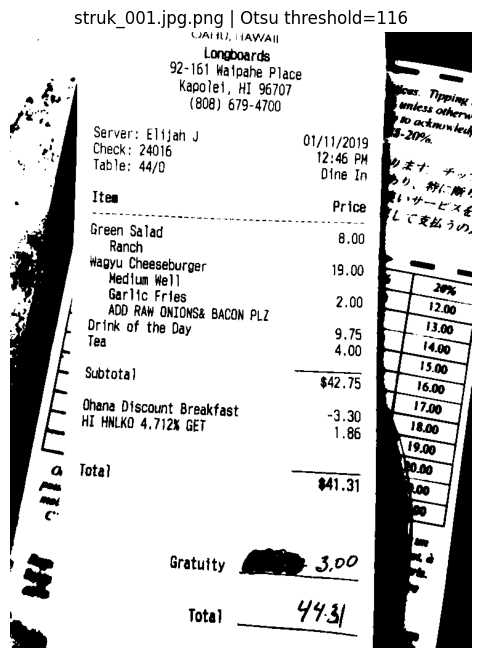

HASIL OCR
--------------------------------------------------
HARU, AYAT
| Longboards
92-161 Haipahe Place —
ae Kapolei, HI 96707 5. Mpping
afte: (808) 679-4700 “mess other,
een kuman
oe server: Elijah J 01/11/2019 5%
+f Check: 24016 12:46 PM WEY
os Table: 44/0 Ding In Bay oom.
Bitte Price PP Ye xg
. re [ae Tees
Pen Green Salad 8.00
Fa Ranch
1 kagyu Cheeseburger 19.00 az -
Medium Well 2%
Garlic Fries 2.00 mM 1209
“7 ADD RAW ONTONS& BACON PLZ ang
Drink of the Day 9.75 | ta
? Tea 4.00 - 00
Subtotal $42.75 Ha
|
Ohana Discount Breakfast 3,30
HI HNLKO 4.712% GET 1.86 pao
— Mp3
@ Total $47.3) oo |
Pen 0
mai po”
c tae
oo ‘
, 3 Gratuity Me 220
, Total 713)
dn ee



In [5]:
import matplotlib.pyplot as plt

sample_path = gray_files[0]
sample = run_otsu_ocr(sample_path)

plt.figure(figsize=(10, 8))
plt.imshow(sample["binary"], cmap="gray")
plt.title(
    f"{sample_path.name} | "
    f"Otsu threshold={sample['otsu_threshold']:.0f}"
)
plt.axis("off")
plt.show()

print("HASIL OCR")
print("-" * 50)
print(sample["text"])

In [6]:
ocr_rows = []

for gray_path in tqdm(gray_files, desc="Otsu + OCR"):
    relative = gray_path.relative_to(GRAY_DIR)

    image_path = OCR_DIR / "Otsu_IMG" / relative
    text_relative = Path(str(relative) + ".txt")
    text_path = OCR_DIR / "OCR_texts" / text_relative

    image_path.parent.mkdir(parents=True, exist_ok=True)
    text_path.parent.mkdir(parents=True, exist_ok=True)

    start_total = perf_counter()

    try:
        result = run_otsu_ocr(gray_path)

        if not cv2.imwrite(str(image_path), result["binary"]):
            raise IOError(f"Gagal menyimpan: {image_path}")

        text_path.write_text(result["text"], encoding="utf-8")

        row = {
            "image": relative.as_posix(),
            "text_file": text_relative.as_posix(),
            "status": "ok",
            "otsu_threshold": result["otsu_threshold"],
            "preprocess_seconds": result["preprocess_seconds"],
            "ocr_seconds": result["ocr_seconds"],
            "total_seconds": perf_counter() - start_total,
            "empty_text": not bool(result["text"].strip()),
            "error": "",
        }

    except Exception as error:
        row = {
            "image": relative.as_posix(),
            "text_file": text_relative.as_posix(),
            "status": "error",
            "total_seconds": perf_counter() - start_total,
            "error": str(error),
        }

    ocr_rows.append(row)

    pd.DataFrame(ocr_rows).to_csv(
        OCR_DIR / "ocr_log.csv",
        index=False,
    )

ocr_log = pd.DataFrame(ocr_rows)

display(ocr_log["status"].value_counts())
display(ocr_log.head())

Otsu + OCR:   0%|          | 0/200 [00:00<?, ?it/s]

,count
status,
ok,192
error,8


,image,text_file,status,otsu_threshold,preprocess_seconds,ocr_seconds,total_seconds,empty_text,error
0,struk_001.jpg.png,struk_001.jpg.png.txt,ok,116.0,0.001439,3.589362,3.649521,False,
1,struk_002.jpg.png,struk_002.jpg.png.txt,ok,84.0,0.000274,2.711201,2.979676,False,
2,struk_003.jpg.png,struk_003.jpg.png.txt,ok,128.0,0.001476,2.257128,2.718152,False,
3,struk_004.jpg.png,struk_004.jpg.png.txt,ok,108.0,0.002269,3.284311,3.781693,False,
4,struk_005.jpg.png,struk_005.jpg.png.txt,ok,147.0,0.000893,2.066635,2.295378,False,


In [8]:
!pip -q install jiwer

from pathlib import Path
import pandas as pd
import unicodedata
import re
import jiwer

PROJECT_DIR = Path("/content/drive/MyDrive/Receipt_OCR_Project")
OCR_DIR = PROJECT_DIR / "Otsu_Classic"

ANNOTATION_PATH = PROJECT_DIR / "annotation.csv"
OCR_LOG_PATH = OCR_DIR / "ocr_log.csv"

assert ANNOTATION_PATH.exists(), (
    f"CSV transkripsi tidak ditemukan: {ANNOTATION_PATH}"
)
assert OCR_LOG_PATH.exists(), (
    f"Log OCR tidak ditemukan: {OCR_LOG_PATH}"
)

annotations = pd.read_csv(
    ANNOTATION_PATH,
    dtype=str,
    keep_default_na=False,
    encoding="utf-8-sig",
)

annotations.columns = annotations.columns.str.strip()

required = {"berkas", "teks_lengkap"}
missing = required - set(annotations.columns)

if missing:
    raise ValueError(
        f"Kolom wajib tidak ditemukan: {missing}. "
        f"Kolom terbaca: {annotations.columns.tolist()}"
    )

ocr_log = pd.read_csv(
    OCR_LOG_PATH,
    dtype=str,
    keep_default_na=False,
    encoding="utf-8-sig",
)

print("Jumlah baris transkripsi:", len(annotations))
print("Jumlah gambar dalam log OCR:", len(ocr_log))

display(annotations[["berkas", "teks_lengkap"]].head(3))

Jumlah baris transkripsi: 200
Jumlah gambar dalam log OCR: 200


,berkas,teks_lengkap
0,struk_001.jpg,"OAHU, HAWAII\nLongboards\n92-161 Waipahe Place..."
1,struk_002.jpg,MARIANACCI'S\nRESTAURANT\nTABLE 403 CHECK\n39\...
2,struk_003.jpg,Dona Mercedes Restaurant\n1030 1/2 San Fernand...


In [10]:
def file_key(value):
    name = str(value).strip().replace("\\", "/")

    while name.startswith("./"):
        name = name[2:]

    # Hanya hapus ekstensi PNG tambahan dari pipeline sebelumnya.
    if name.lower().endswith((".jpg.png", ".jpeg.png")):
        name = name[:-4]

    return name


annotations["file_key"] = annotations["berkas"].map(file_key)
ocr_log["file_key"] = ocr_log["image"].map(file_key)

if annotations["file_key"].eq("").any():
    raise ValueError("Ada kolom berkas yang kosong pada CSV anotasi.")

for label, table in [
    ("CSV anotasi", annotations),
    ("log OCR", ocr_log),
]:
    duplicate = table["file_key"].duplicated(keep=False)

    if duplicate.any():
        display(table.loc[duplicate])
        raise ValueError(
            f"Ada nama berkas duplikat pada {label}. "
            "Perbaiki sebelum evaluasi."
        )

paired = annotations.merge(
    ocr_log[["file_key", "status", "text_file"]],
    on="file_key",
    how="left",
    validate="one_to_one",
    indicator=True,
)

unmatched = paired.loc[paired["_merge"].eq("left_only")]

print("Anotasi cocok dengan log OCR:",
      int(paired["_merge"].eq("both").sum()))
print("Anotasi tidak ditemukan di log OCR:", len(unmatched))

if not unmatched.empty:
    display(unmatched[["berkas", "file_key"]])

without_annotation = ~ocr_log["file_key"].isin(
    annotations["file_key"]
)

print(
    "Gambar OCR tanpa anotasi:",
    int(without_annotation.sum())
)

Anotasi cocok dengan log OCR: 200
Anotasi tidak ditemukan di log OCR: 0
Gambar OCR tanpa anotasi: 0


In [18]:
def normalize_text(text):
    text = unicodedata.normalize("NFC", str(text))
    return re.sub(r"\s+", " ", text).strip()


rows = []

for _, row in paired.iterrows():
    item = {
        "berkas": row["berkas"],
        "file_key": row["file_key"],
    }

    reference = normalize_text(row["teks_lengkap"])

    if row["_merge"] != "both":
        rows.append({
            **item,
            "evaluation_status": "no_ocr_match",
        })
        continue

    if not reference:
        rows.append({
            **item,
            "evaluation_status": "empty_ground_truth",
        })
        continue

    if row["status"] != "ok":
        rows.append({
            **item,
            "evaluation_status": "ocr_error",
        })
        continue

    prediction_path = OCR_DIR / "OCR_texts" / row["text_file"]

    if not prediction_path.is_file():
        rows.append({
            **item,
            "evaluation_status": "prediction_file_missing",
        })
        continue

    try:
        hypothesis = normalize_text(
            prediction_path.read_text(encoding="utf-8-sig")
        )

        char_result = jiwer.process_characters(
            reference, hypothesis
        )
        word_result = jiwer.process_words(
            reference, hypothesis
        )

        char_edits = (
            char_result.substitutions
            + char_result.deletions
            + char_result.insertions
        )

        word_edits = (
            word_result.substitutions
            + word_result.deletions
            + word_result.insertions
        )

        rows.append({
            **item,
            "evaluation_status": "evaluated",
            "reference_text": reference,
            "prediction_text": hypothesis,
            "empty_prediction": hypothesis == "",
            "reference_characters": len(reference),
            "reference_words": len(reference.split()),
            "character_edits": char_edits,
            "word_edits": word_edits,
            "cer_percent": 100 * char_result.cer,
            "wer_percent": 100 * word_result.wer,
            "exact_text_match": reference == hypothesis,
        })

    except Exception as error:
        rows.append({
            **item,
            "evaluation_status": "evaluation_error",
            "error": str(error),
        })

metrics = pd.DataFrame(rows)

metrics.to_csv(
    OCR_DIR / "metrics_from_csv_per_image.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Status evaluasi:")
display(metrics["evaluation_status"].value_counts())

evaluated = metrics.loc[
    metrics["evaluation_status"].eq("evaluated")
].copy()

if not evaluated.empty:
    display(
        evaluated[
            ["berkas", "cer_percent", "wer_percent",
             "exact_text_match"]
        ].head(10)
    )

Status evaluasi:


,count
evaluation_status,
evaluated,192
ocr_error,8


,berkas,cer_percent,wer_percent,exact_text_match
0,struk_001.jpg,49.134199,100.000000,False
1,struk_002.jpg,83.548387,98.214286,False
2,struk_003.jpg,35.690236,106.122449,False
3,struk_004.jpg,47.738693,80.000000,False
4,struk_005.jpg,20.855615,48.571429,False
5,struk_006.jpg,50.275229,83.950617,False
6,struk_007.jpg,91.919192,98.387097,False
7,struk_008.jpg,54.397394,103.571429,False
8,struk_009.jpg,54.723127,86.000000,False
9,struk_010.jpg,36.639118,61.904762,False


In [19]:
summary = {
    "annotation_rows": len(annotations),
    "ocr_log_images": len(ocr_log),
    "ocr_errors_in_log": int(
        ocr_log["status"].ne("ok").sum()
    ),
    "evaluated_images": len(evaluated),
    "annotation_rows_not_evaluated": (
        len(metrics) - len(evaluated)
    ),
    "ocr_images_without_annotation": int(
        (~ocr_log["file_key"].isin(
            annotations["file_key"]
        )).sum()
    ),
    "normalization": (
        "NFC; collapse whitespace; case-sensitive; "
        "preserve punctuation"
    ),
}

if not evaluated.empty:
    summary.update({
        "corpus_cer_percent": (
            100 * evaluated["character_edits"].sum()
            / evaluated["reference_characters"].sum()
        ),
        "corpus_wer_percent": (
            100 * evaluated["word_edits"].sum()
            / evaluated["reference_words"].sum()
        ),
        "mean_image_cer_percent": (
            evaluated["cer_percent"].mean()
        ),
        "mean_image_wer_percent": (
            evaluated["wer_percent"].mean()
        ),
        "exact_text_match_percent": (
            100 * evaluated["exact_text_match"].mean()
        ),
    })

summary_df = pd.DataFrame([summary])

summary_df.to_csv(
    OCR_DIR / "metrics_from_csv_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

display(summary_df.T.rename(columns={0: "value"}))

if evaluated.empty:
    print(
        "Belum ada pasangan yang berhasil dievaluasi. "
        "Periksa status pada sel sebelumnya."
    )

,value
annotation_rows,200
ocr_log_images,200
ocr_errors_in_log,8
evaluated_images,192
annotation_rows_not_evaluated,8
ocr_images_without_annotation,0
normalization,NFC; collapse whitespace; case-sensitive; pres...
corpus_cer_percent,81.550032
corpus_wer_percent,145.634635
mean_image_cer_percent,79.792275
